In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
path = '/content/drive/MyDrive/ML2026/PRAKTIKUM7'

# pastikan folder keluaran ada
os.makedirs(path + '/MODEL', exist_ok=True)
os.makedirs(path + '/REPORT', exist_ok=True)
print(os.listdir(path))

Mounted at /content/drive
['DATA', 'NOTEBOOK', 'MODEL', 'REPORT']


In [2]:
import pandas as pd

# membaca file csv dari folder DATA di Google Drive
df = pd.read_csv(path + '/DATA/dataset_college.csv')
df.head()

,StudentID,Gender,Parent_income,IQ,Encourage,Plan
0,4558,male,53900,118,encourage,plan
1,4561,female,24900,87,not encourage,not plan
2,4563,female,65800,93,not encourage,not plan
3,4565,male,11440,117,encourage,plan
4,4567,female,16700,102,not encourage,not plan


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   StudentID      8000 non-null   int64 
 1   Gender         8000 non-null   object
 2   Parent_income  8000 non-null   int64 
 3   IQ             8000 non-null   int64 
 4   Encourage      8000 non-null   object
 5   Plan           8000 non-null   object
dtypes: int64(3), object(3)
memory usage: 375.1+ KB


In [4]:
df.describe()

,StudentID,Parent_income,IQ
count,8000.00000,8000.000000,8000.000000
mean,4000.50000,40584.017500,99.577750
std,2309.54541,18031.506468,18.923655
min,1.00000,4500.000000,60.000000
25%,2000.75000,29400.000000,90.000000
50%,4000.50000,39330.000000,100.000000
75%,6000.25000,51592.500000,110.000000
max,8000.00000,82390.000000,140.000000


In [5]:
print(f"Gender : {df['Gender'].unique()}")
print(f"Encourage : {df['Encourage'].unique()}")
print(f"Plan : {df['Plan'].unique()}")

Gender : ['male' 'female']
Encourage : ['encourage' 'not encourage']
Plan : ['plan' 'not plan']


<Axes: >

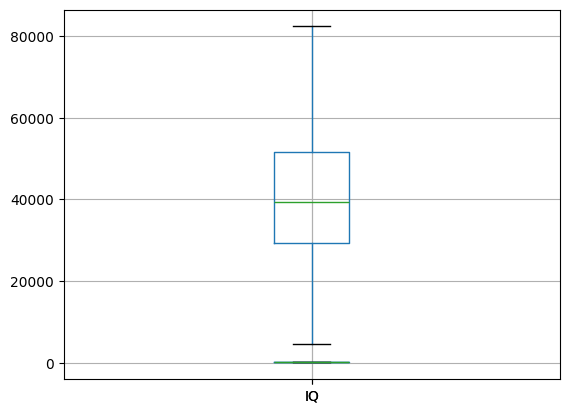

In [6]:
df.boxplot(column=['Parent_income'])
df.boxplot(column=['IQ'])

In [7]:
df['Plan'].value_counts()

,count
Plan,
not plan,5404
plan,2596


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

,0
StudentID,0
Gender,0
Parent_income,0
IQ,0
Encourage,0
Plan,0


In [10]:
# Menghapus baris yang memiliki missing values
df = df.dropna().copy()

# One-Hot Encoding
df = pd.get_dummies(
    df,
    columns=['Gender', 'Encourage'],
    dtype=int
)

# Menampilkan hasil cleaning
display(df.head())

,StudentID,Parent_income,IQ,Plan,Gender_female,Gender_male,Encourage_encourage,Encourage_not encourage
0,4558,53900,118,plan,0,1,1,0
1,4561,24900,87,not plan,1,0,0,1
2,4563,65800,93,not plan,1,0,0,1
3,4565,11440,117,plan,0,1,1,0
4,4567,16700,102,not plan,1,0,0,1


In [11]:
X = df[['Parent_income', 'IQ', 'Gender_female', 'Gender_male', 'Encourage_encourage',
        'Encourage_not encourage']]
y = df['Plan']

print("Fitur X:", X.columns.tolist())
print("Target y:", y.name)
print("\nDistribusi target Plan:")
print(y.value_counts())

Fitur X: ['Parent_income', 'IQ', 'Gender_female', 'Gender_male', 'Encourage_encourage', 'Encourage_not encourage']
Target y: Plan

Distribusi target Plan:
Plan
not plan    5404
plan        2596
Name: count, dtype: int64


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 6400
Jumlah data testing: 1600


In [13]:
from sklearn.ensemble import RandomForestClassifier

# Membuat model
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced',
    bootstrap=True,
    max_depth=None,
    max_features='sqrt',
    criterion='gini',
    warm_start=False,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    oob_score=True
)

# Training model
model.fit(X_train, y_train)

print("Model Random Forest berhasil dilatih!")

Model Random Forest berhasil dilatih!


Akurasi: 0.8087 (80.88%)

Classification Report:
              precision    recall  f1-score   support

    not plan       0.84      0.88      0.86      1081
        plan       0.73      0.66      0.69       519

    accuracy                           0.81      1600
   macro avg       0.79      0.77      0.78      1600
weighted avg       0.81      0.81      0.81      1600



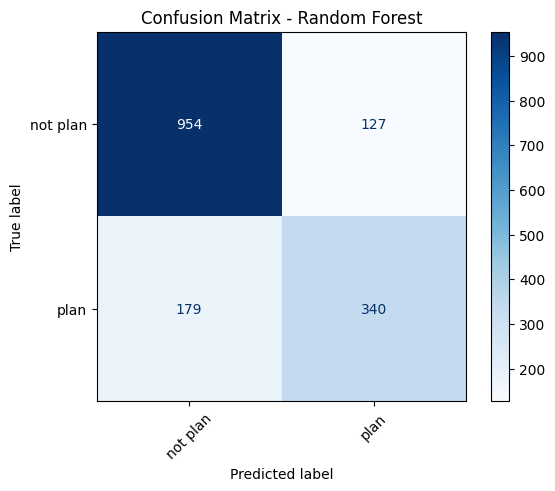

In [14]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Prediksi data testing
y_pred = model.predict(X_test)

# Menghitung akurasi
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi: {akurasi:.4f} ({akurasi * 100:.2f}%)")

# Evaluasi precision, recall, dan F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title('Confusion Matrix - Random Forest')

# simpan gambar ke folder REPORT
plt.savefig(path + '/REPORT/confusion_matrix_rf.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
import joblib

# Simpan model dan daftar fitur ke folder MODEL
paket_model = {
    'model': model,
    'fitur': X_train.columns.tolist()
}

joblib.dump(paket_model, path + '/MODEL/random_forest_plan.pkl')

print("Model dan daftar fitur berhasil disimpan!")

Model dan daftar fitur berhasil disimpan!


In [16]:
# Load model
paket_model = joblib.load(path + '/MODEL/random_forest_plan.pkl')

model_loaded = paket_model['model']
fitur_model = paket_model['fitur']

print("Model berhasil dimuat kembali!")
print("Fitur model:", fitur_model)

Model berhasil dimuat kembali!
Fitur model: ['Parent_income', 'IQ', 'Gender_female', 'Gender_male', 'Encourage_encourage', 'Encourage_not encourage']


In [17]:
def prediksi_plan(parent_income, iq, gender, encourage):

    # 1. Membuat data baru dengan format asli
    data_baru = pd.DataFrame([{
        'Parent_income': parent_income,
        'IQ': iq,
        'Gender': gender,
        'Encourage': encourage
    }])

    # 2. One-Hot Encoding
    data_encoded = pd.get_dummies(
        data_baru,
        columns=['Gender', 'Encourage'],
        dtype=int
    )

    # 3. Menyamakan kolom dengan data training
    data_encoded = data_encoded.reindex(
        columns=fitur_model,
        fill_value=0
    )

    # 4. Prediksi
    hasil = model_loaded.predict(data_encoded)

    # 5. Probabilitas prediksi
    probabilitas = model_loaded.predict_proba(data_encoded)

    print("Data asli:")
    display(data_baru)

    print("Hasil prediksi Plan:", hasil[0])

    print("\nProbabilitas setiap kelas:")
    for kelas, prob in zip(model_loaded.classes_, probabilitas[0]):
        print(f"{kelas}: {prob:.2%}")

    return hasil[0]

In [18]:
hasil = prediksi_plan(
    parent_income=50000,
    iq=110,
    gender='female',
    encourage='encourage'
)

Data asli:


,Parent_income,IQ,Gender,Encourage
0,50000,110,female,encourage


Hasil prediksi Plan: plan

Probabilitas setiap kelas:
not plan: 9.00%
plan: 91.00%
